# Hedging one call: a simple Heston example

**The problem:** we have sold a call option. In 30 days, we owe the amount by which the stock price exceeds the strike $K=100$:

$$Z=\max(S_T-K,0).$$

**Hedging** means buying and selling assets before that date so their gains help pay this bill. For example, holding $0.5$ shares during a stock-price rise of $2$ dollars earns $1$ dollar. A neural network learns the holdings to choose each day.

We measure

$$L=\text{option payment}-\text{trading gain}+\text{trading costs}.$$

A smaller $L$ is better for a fixed option premium. Our plots show loss **before** receiving that premium: if we charge $p$, the final profit is $p-L$.

This notebook loads saved results. **Run All draws the figures; it does not train.**

In [1]:
from scripts.general_nn import generalNN
from scripts import plots

paper = generalNN.from_saved("paper_full")
control = generalNN.from_saved("paper_stock")
ours = generalNN.from_saved("ours")

## 1. First, the original paper

These are original figures from [Buehler et al., *Deep Hedging* (2018)](https://arxiv.org/abs/1802.03042). They answer two different questions.

- **CVaR at $50\%$:** how large is the average loss in the worst half of outcomes? With a threshold $w$, its sample formula is

$$\widehat{\operatorname{CVaR}}_{0.5}(L)=\min_w\left[w+\frac{2}{N}\sum_{i=1}^{N}\max(L_i-w,0)\right].$$

- **Entropic risk:** how costly are large losses when we give them exponential weight? In our finite test sample with $\lambda=1$,

$$\widehat\rho_1(L)=\log\left(\frac{1}{N}\sum_{i=1}^{N}e^{L_i}\right).$$

We adjust the network weights to reduce the chosen risk score. One very bad hedge can strongly affect the entropic score. The paragraphs under the original figures explain their settings.

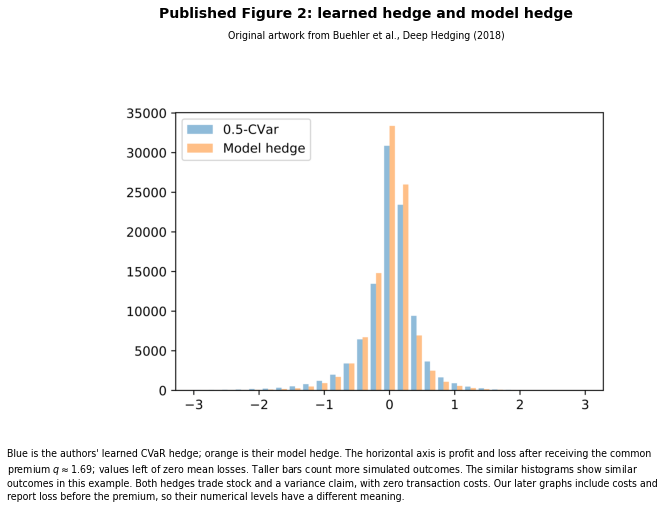

In [2]:
plots.show_published_figure(2)

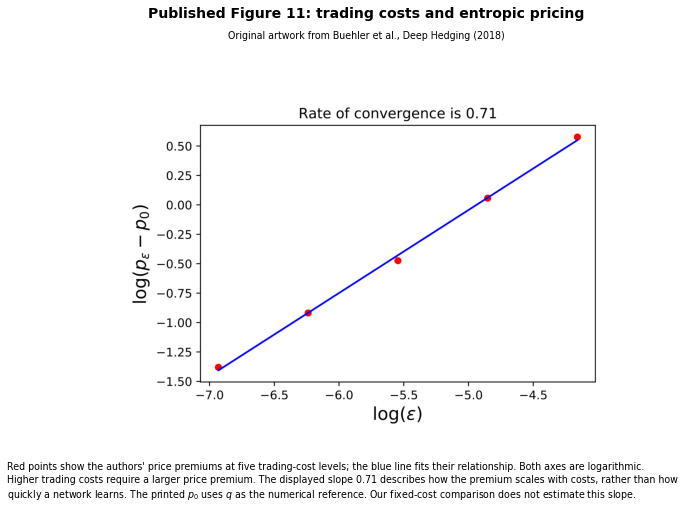

In [3]:
plots.show_published_figure(11)

## 2. Now, our experiment

We use synthetic Heston stock paths, one call with $S_0=K=100$, 30 daily decisions, zero interest, and trading costs $c=0.001$. In the Heston model, both the stock price and its variance change randomly. The additional variance contract gives the two-asset model another way to manage that risk.

Here, `paper` means our reconstruction of the paper's network under a common simulation and training protocol. All three designs use the same $65{,}536$ test paths. We train each design for both risk objectives and repeat training three times.

| Design | Assets it can trade | Network at each date | Total network parameters |
|---|---|---|---:|
| Paper style: full | Stock and variance claim | $4\to17\to17\to2$, ReLU and batch normalization | $14{,}850$ |
| Paper style: stock control | Stock; variance holding fixed at zero | Same paper-style network | $14{,}850$ |
| Ours | Stock | $3\to16\to16\to1$, Tanh hidden layers | $10{,}590$ |

Each trading date has its own small network. Inputs describe the stock price, current variance, and previous holdings. Our implementation rescales its price and variance inputs. All date-specific networks learn together from the final loss.

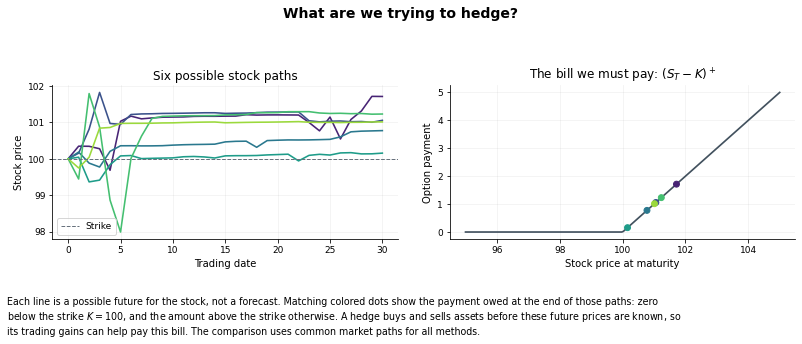

In [4]:
plots.plot_paths(ours)

### Learning and outcomes for our stock-only network

The network first receives a CVaR warm-up. We then copy those weights into two equally long continuations: one keeps training for CVaR; the other trains for entropic risk. Validation paths choose the checkpoints. Separate test paths provide the final assessment.

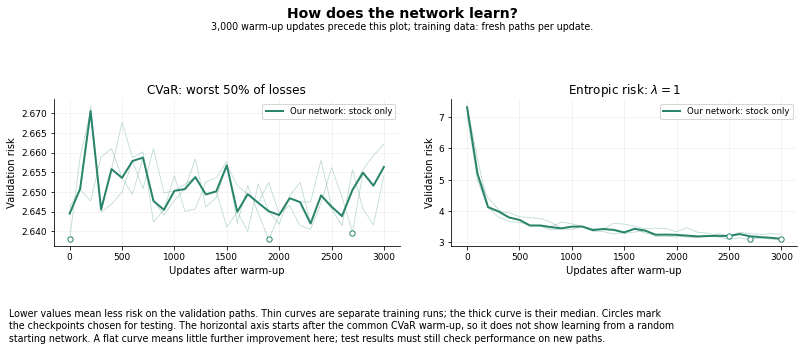

In [5]:
plots.plot_learning(ours)

**What this shows:** after the warm-up, our CVaR curve changes very little, while the entropic curve falls from about $7.3$ to $3.1$. Training for a different objective changes the hedge. Compare progress within each panel: the two panels use different risk formulas.

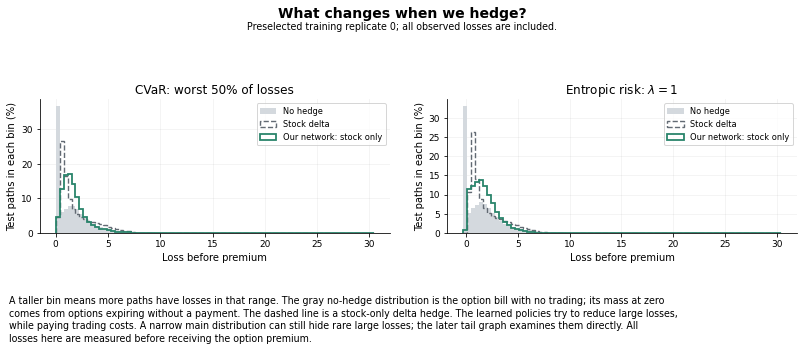

In [6]:
plots.plot_losses(ours)

## 3. Compare under common conditions

The next figures compare our **saved implementations**, using the same costs, risk definitions, and test scenarios.

Comparing the two paper-style designs tests access to variance trading. Comparing the stock control with ours tests two stock-only implementations, including their different networks and input scaling. These comparisons do not overlay our numbers on the authors' published figures.

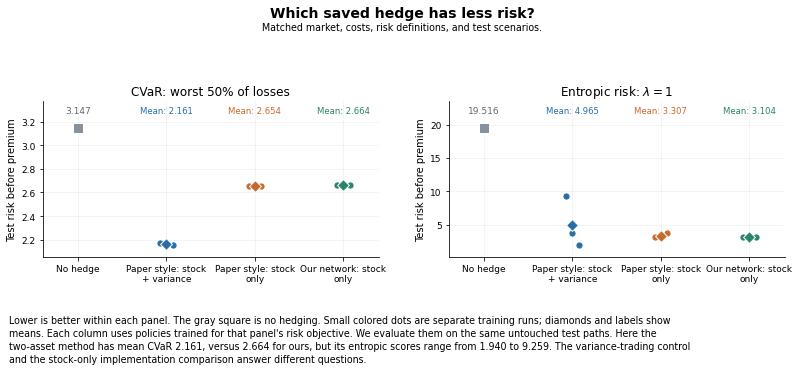

In [7]:
plots.plot_risk([paper, control, ours])

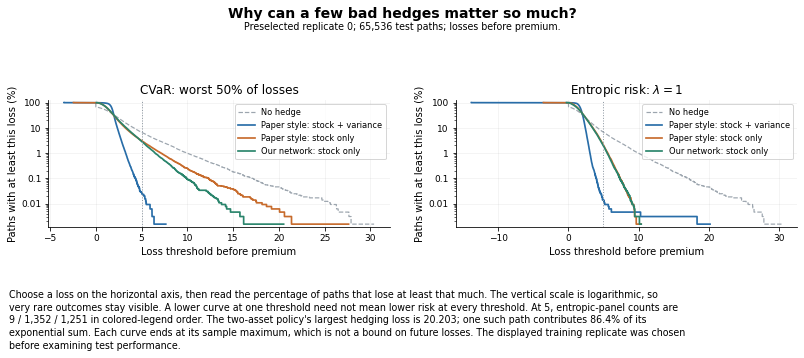

In [8]:
plots.plot_loss_tails([paper, control, ours])

### What have we learned from these saved runs?

- Our stock-only design achieves almost the same mean CVaR as the stock-only paper control: $2.664$ versus $2.654$.
- Our stock-only design has $10{,}590$ network parameters versus $14{,}850$ in the paper-style design. It also avoids trading the variance contract.
- Our three entropic runs score $3.085$–$3.113$ on the main test sample: a smaller spread than the full model's $1.940$–$9.259$. These are sampled outcomes from three training runs, not a general stability guarantee.
- The two-asset model achieves lower mean CVaR: $2.161$ versus $2.664$ for ours. Extra instruments can help, while successful training and rare-loss control remain separate challenges.

This is a one-call teaching experiment. Larger portfolios and portfolio compression remain future work.

## 4. Reuse the same plotting functions

The plotting interface is the same for either experiment. These examples are shown as text so they do not add repeated figures to Run All:

```python
plots.plot_learning(ours)
plots.plot_learning(paper)
plots.plot_losses(paper)
plots.plot_risk([paper, ours])
```

The same single-object/list interface also applies to `plot_paths` and `plot_loss_tails`. List comparisons check that the market, costs, risk definitions, and test data match.

### Optional: train a small new experiment

Copy this example into a new code cell when you want to train. Its short budget is for practice; it does not reproduce the saved benchmark.

```python
from scripts.settings import Settings

settings = Settings(
    warmup_updates=100,
    continuation_updates=100,
    number_of_replicates=1,
    normalization_size=2048,
    validation_size=2048,
    test_size=8192,
    static_training_size=8192,
)

trial = generalNN(method="ours", settings=settings, dynamic_data=True, name="Fresh batches")
trial.train()
validation_scores = trial.validate()
trial.evaluate()
plots.plot_learning(trial)
trial.save("results/my_trial")
```

`dynamic_data=True` generates fresh paths at every update. `dynamic_data=False` samples batches from a fixed training pool. **The flag changes the training data, not whether the hedge trades over time.** Both modes keep validation and test data separate. Raw batches are retained only if `retain_training_batches=True`; by default the object keeps histories, scores, and batch records.

The [code guide](docs/code_guide.md) explains settings, stored data, trained models, saving, and loading.